In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

train = pd.read_parquet(ROOT / "data" / "processed" / "train.parquet")

exclude = ["SK_ID_CURR", "TARGET", "IS_KAGGLE_TEST"]
features = [c for c in train.columns if c not in exclude]
cat_cols = [c for c in features if not pd.api.types.is_numeric_dtype(train[c])]
for c in cat_cols:
    train[c] = train[c].astype("category")     # LightGBM handles categories itself

X, y = train[features], train["TARGET"]
print(X.shape, len(cat_cols), "categorical")


(215257, 105) 13 categorical


In [2]:
params = dict(
    objective="binary", metric="auc",
    learning_rate=0.05, num_leaves=31, min_child_samples=100,
    feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
    scale_pos_weight=(y == 0).sum() / (y == 1).sum(),
    seed=42, verbose=-1, num_threads=4,
)
dtrain = lgb.Dataset(X, y, categorical_feature=cat_cols, free_raw_data=False)

cv = lgb.cv(params, dtrain, num_boost_round=3000, nfold=5, stratified=True, seed=42,
            callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)])

best_rounds = len(cv["valid auc-mean"])
cv_auc = cv["valid auc-mean"][-1]
print(f"\nbest number of trees = {best_rounds}")
print(f"CV AUC = {cv_auc:.3f}   CV Gini = {2*cv_auc - 1:.3f}")


Training until validation scores don't improve for 100 rounds
[100]	valid's auc: 0.769982 + 0.00462893
[200]	valid's auc: 0.773986 + 0.00458188
[300]	valid's auc: 0.774349 + 0.00435885
Early stopping, best iteration is:
[268]	valid's auc: 0.774409 + 0.00446187

best number of trees = 268
CV AUC = 0.774   CV Gini = 0.549


In [3]:
gbm = lgb.train(params, dtrain, num_boost_round=best_rounds)

train_auc = roc_auc_score(y, gbm.predict(X))
print(f"Train Gini = {2*train_auc - 1:.3f}")
print(f"CV    Gini = {2*cv_auc - 1:.3f}")
print(f"Scorecard train Gini = 0.511")


Train Gini = 0.687
CV    Gini = 0.549
Scorecard train Gini = 0.511


In [6]:
import shap, json

sample = X.sample(20000, random_state=42)
explainer = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(sample)
if isinstance(shap_values, list):          # older shap versions return [class 0, class 1]
    shap_values = shap_values[1]

print(shap_values.shape)


(20000, 105)


/home/fiza/Credit_Risk/.venv/lib/python3.12/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [7]:
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=features).sort_values(ascending=False)

with open(ROOT / "models" / "lr_model.json") as f:
    scorecard_features = json.load(f)["features"]

top = importance.head(20).to_frame("mean_abs_shap").round(3)
top["in_scorecard"] = [f in scorecard_features for f in top.index]
print("Rank of protected features:",
      importance.rank(ascending=False)[["CODE_GENDER", "NAME_FAMILY_STATUS"]].astype(int).to_dict())
top


Rank of protected features: {'CODE_GENDER': 9, 'NAME_FAMILY_STATUS': 25}


,mean_abs_shap,in_scorecard
EXT_SOURCE_2,0.340,True
EXT_SOURCE_3,0.313,True
EXT_SOURCE_1,0.162,True
ORGANIZATION_TYPE,0.147,True
BUREAU_DEBT_TO_CREDIT,0.135,True
AMT_CREDIT_TO_GOODS_RATIO,0.133,True
PREV_GRANTED_TO_REQUESTED,0.114,True
YEARS_EMPLOYED,0.109,True
CODE_GENDER,0.094,False
BUREAU_ACTIVE_COUNT,0.087,True


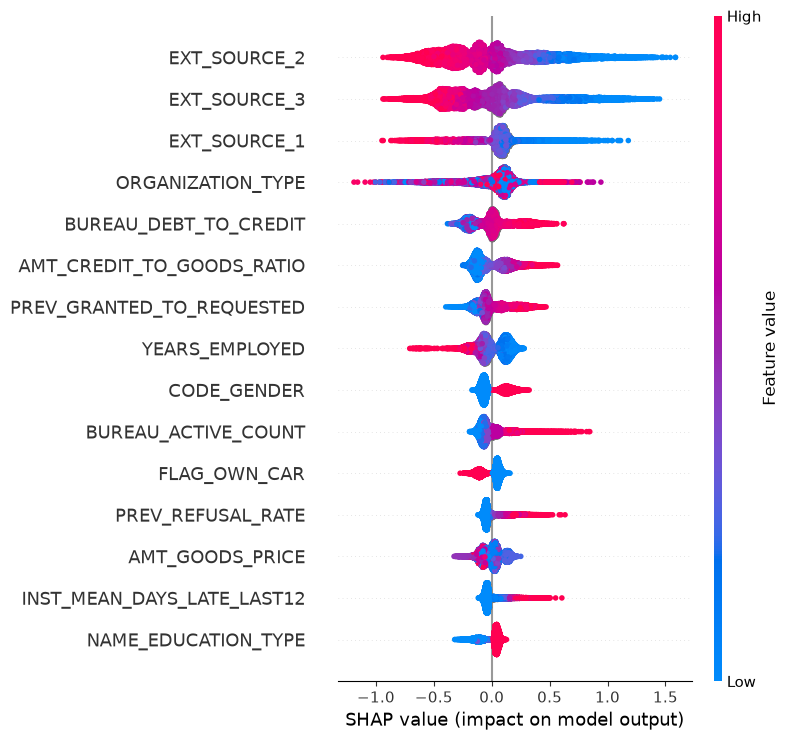

In [8]:
plot_data = sample.copy()
for c in cat_cols:
    plot_data[c] = plot_data[c].cat.codes      # plot needs numbers; colours for text columns aren't meaningful
shap.summary_plot(shap_values, plot_data, max_display=15)


In [9]:
fair = [f for f in features if f not in ["CODE_GENDER", "NAME_FAMILY_STATUS"]]
fair_cats = [c for c in cat_cols if c in fair]

cv_fair = lgb.cv(params, lgb.Dataset(X[fair], y, categorical_feature=fair_cats),
                 num_boost_round=3000, nfold=5, stratified=True, seed=42,
                 callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)])

fair_auc = cv_fair["valid auc-mean"][-1]
print(f"\nFair LightGBM CV Gini = {2*fair_auc - 1:.3f}")
print(f"LightGBM with gender  = {2*cv_auc - 1:.3f}")
print(f"Scorecard (train)     = 0.511")


Training until validation scores don't improve for 100 rounds
[100]	valid's auc: 0.768625 + 0.00389229
[200]	valid's auc: 0.772525 + 0.00379075
[300]	valid's auc: 0.772805 + 0.00361126
Early stopping, best iteration is:
[272]	valid's auc: 0.772928 + 0.00344737

Fair LightGBM CV Gini = 0.546
LightGBM with gender  = 0.549
Scorecard (train)     = 0.511
